# Lector de Matriculas OCRs

In [6]:
import cv2
import csv
import time
import gc
import easyocr
import pandas as pd
from PIL import Image
from transformers import AutoProcessor, AutoModelForCausalLM

# -----------------------------------------------------------------------------
# 1. CARGA DE MOTORES OCR
# -----------------------------------------------------------------------------
print("Cargando EasyOCR...")
lector_easyocr = easyocr.Reader(['en'], gpu=False)

print("Cargando Florence-2...")
modelo_id = "microsoft/Florence-2-base"
modelo_florence = AutoModelForCausalLM.from_pretrained(
    modelo_id, 
    trust_remote_code=True, 
    attn_implementation="eager"
)
procesador = AutoProcessor.from_pretrained(modelo_id, trust_remote_code=True)
tarea_prompt = "<OCR>"

# -----------------------------------------------------------------------------
# 2. CONFIGURACIÓN DE ARCHIVOS
# -----------------------------------------------------------------------------
video_path = 'video_test.mp4'
csv_entrada = 'resultados_deteccion.csv'
csv_salida = 'resultados_finales_con_ocr.csv'

df_detecciones = pd.read_csv(csv_entrada)
cap = cv2.VideoCapture(video_path)
fps = cap.get(cv2.CAP_PROP_FPS)

# Cabecera oficial respetando los requerimientos de la parte B
cabecera = [
    "fotograma", "tiempo_segundos", "tipo_objeto", "confianza_yolo", "identificador_tracking", 
    "x1", "y1", "x2", "y2", "ocr_motor", "confianza_ocr", 
    "tiempo_procesamiento_ms", "mx1", "my1", "mx2", "my2", "texto_matricula"
]

with open(csv_salida, mode='w', newline='', encoding='utf-8') as f:
    writer = csv.writer(f)
    writer.writerow(cabecera)

print(f"\nIniciando procesamiento de OCR sobre '{csv_entrada}'...\n")

# Filtramos solo detecciones válidas de matrícula
df_matriculas = df_detecciones[df_detecciones['matricula_detectada'].astype(str).str.upper() == 'TRUE'].copy()

frame_actual = -1
frame_img = None
total_procesadas = 0

# -----------------------------------------------------------------------------
# 3. BUCLE PRINCIPAL DE EXTRACCIÓN DE TEXTO
# -----------------------------------------------------------------------------
for idx, row in df_matriculas.iterrows():
    num_frame = int(row['fotograma'])
    
    # Cargar el fotograma solo cuando cambia la posición en el vídeo
    if num_frame != frame_actual:
        cap.set(cv2.CAP_PROP_POS_FRAMES, num_frame - 1)
        ret, frame_img = cap.read()
        frame_actual = num_frame
        if not ret:
            continue

    try:
        mx1, my1 = int(row['mx1']), int(row['my1'])
        mx2, my2 = int(row['mx2']), int(row['my2'])
    except ValueError:
        continue

    recorte_bgr = frame_img[my1:my2, mx1:mx2]
    if recorte_bgr.size == 0:
        continue

    tiempo_seg = round(num_frame / fps, 2)
    track_id = row['identificador_tracking']
    tipo_obj = row['tipo_objeto']
    conf_yolo = row['confianza']
    x1, y1, x2, y2 = row['x1'], row['y1'], row['x2'], row['y2']

    # -------------------------------------------------------------------------
    # A) EVALUACIÓN CON EASYOCR
    # -------------------------------------------------------------------------
    t_easy_in = time.time()
    res_easy = lector_easyocr.readtext(recorte_bgr)
    t_easy_ms = round((time.time() - t_easy_in) * 1000, 2)
    
    texto_easy = res_easy[0][1] if res_easy else ""
    conf_ocr_easy = round(float(res_easy[0][2]), 3) if res_easy else 0.0

    # -------------------------------------------------------------------------
    # B) EVALUACIÓN CON FLORENCE-2
    # -------------------------------------------------------------------------
    t_flo_in = time.time()
    recorte_rgb = cv2.cvtColor(recorte_bgr, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(recorte_rgb)
    inputs = procesador(text=tarea_prompt, images=pil_img, return_tensors="pt")
    
    generated_ids = modelo_florence.generate(
        input_ids=inputs["input_ids"],
        pixel_values=inputs["pixel_values"],
        max_new_tokens=1024,
        num_beams=3,
        use_cache=False
    )
    gen_text = procesador.batch_decode(generated_ids, skip_special_tokens=False)[0]
    res_flo = procesador.post_process_generation(gen_text, task=tarea_prompt, image_size=(pil_img.width, pil_img.height))
    texto_flo = res_flo.get(tarea_prompt, "").strip()
    t_flo_ms = round((time.time() - t_flo_in) * 1000, 2)
    
    # Florence-2 no emite confianza numérica previa
    conf_ocr_flo = "N/A"

    # -------------------------------------------------------------------------
    # C) GUARDA DIRECTA EN DISCO EN TIEMPO REAL
    # -------------------------------------------------------------------------
    with open(csv_salida, mode='a', newline='', encoding='utf-8') as f:
        writer = csv.writer(f)
        
        # Fila Florence-2
        writer.writerow([
            num_frame, tiempo_seg, tipo_obj, conf_yolo, track_id,
            x1, y1, x2, y2, "Florence-2", conf_ocr_flo, t_flo_ms,
            mx1, my1, mx2, my2, texto_flo
        ])
        
        # Fila EasyOCR
        writer.writerow([
            num_frame, tiempo_seg, tipo_obj, conf_yolo, track_id,
            x1, y1, x2, y2, "EasyOCR", conf_ocr_easy, t_easy_ms,
            mx1, my1, mx2, my2, texto_easy
        ])

    total_procesadas += 1
    print(f"Frame {num_frame} | ID {track_id} | Flo2 ({t_flo_ms}ms): '{texto_flo}' | Easy ({conf_ocr_easy}): '{texto_easy}'")

    if total_procesadas % 20 == 0:
        gc.collect()

cap.release()
print(f"\n¡Ejecución finalizada! {total_procesadas} capturas registradas en '{csv_salida}'.")

Using CPU. Note: This module is much faster with a GPU.


Cargando EasyOCR...
Cargando Florence-2...

Iniciando procesamiento de OCR sobre 'resultados_deteccion.csv'...

Frame 8 | ID 1 | Flo2 (2915.73ms): '3' | Easy (0.0): ''
Frame 9 | ID 1 | Flo2 (2703.23ms): '2' | Easy (0.0): ''
Frame 10 | ID 1 | Flo2 (2756.44ms): '2' | Easy (0.0): ''
Frame 11 | ID 1 | Flo2 (2612.38ms): '2522' | Easy (0.0): ''
Frame 12 | ID 1 | Flo2 (2615.93ms): '2522' | Easy (0.0): ''
Frame 13 | ID 1 | Flo2 (2649.34ms): '1' | Easy (0.0): ''
Frame 14 | ID 1 | Flo2 (2650.09ms): '2222' | Easy (0.0): ''
Frame 15 | ID 1 | Flo2 (2716.44ms): '2727' | Easy (0.0): ''
Frame 16 | ID 1 | Flo2 (2699.73ms): '2' | Easy (0.0): ''
Frame 17 | ID 1 | Flo2 (2929.97ms): '٠٠' | Easy (0.0): ''
Frame 18 | ID 1 | Flo2 (3016.64ms): '٠٠' | Easy (0.0): ''
Frame 19 | ID 1 | Flo2 (2737.12ms): '2727' | Easy (0.0): ''
Frame 20 | ID 1 | Flo2 (2820.48ms): '2727' | Easy (0.0): ''
Frame 21 | ID 1 | Flo2 (2616.57ms): '1' | Easy (0.0): ''
Frame 22 | ID 1 | Flo2 (2766.67ms): 'Kiss' | Easy (0.0): ''
Frame 23 | I

c:\Users\xStrikePC\anaconda3\envs\VC_P4b\lib\site-packages\torch\utils\data\dataloader.py:666: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Frame 765 | ID 14 | Flo2 (3266.16ms): '1213 LVC' | Easy (0.123): 'DTL'
Frame 766 | ID 14 | Flo2 (3329.8ms): '72LKE' | Easy (0.0): ''
Frame 767 | ID 14 | Flo2 (3245.45ms): '2132LIC' | Easy (0.087): 'LD'
Frame 768 | ID 14 | Flo2 (3119.41ms): '12LKC' | Easy (0.0): ''
Frame 769 | ID 14 | Flo2 (3266.41ms): '512LKC' | Easy (0.0): ''
Frame 770 | ID 14 | Flo2 (3262.27ms): 'S73UKC' | Easy (0.0): ''
Frame 771 | ID 14 | Flo2 (3233.71ms): '5713LKC' | Easy (0.03): '@q'
Frame 772 | ID 14 | Flo2 (3264.6ms): '137LKC' | Easy (0.115): 'm'
Frame 773 | ID 14 | Flo2 (3322.43ms): 'S73LKC' | Easy (0.079): 'MAd'
Frame 774 | ID 14 | Flo2 (3299.95ms): '3713 LKC' | Easy (0.073): 'pq'
Frame 775 | ID 14 | Flo2 (3267.75ms): '3713 LKC' | Easy (0.34): 'JL'
Frame 776 | ID 14 | Flo2 (3399.99ms): '1234KC' | Easy (0.236): 'mm'
Frame 777 | ID 14 | Flo2 (3317.76ms): '3713 LKC' | Easy (0.087): 'MEEg'
Frame 778 | ID 14 | Flo2 (3216.63ms): '375LKC' | Easy (0.066): 'Hkg'
Frame 779 | ID 14 | Flo2 (3208.21ms): '3713 NYC' | Easy 

# Creación de Datos reales


In [17]:
import pandas as pd

csv_resultados = 'resultados_finales_con_ocr.csv'
csv_ground_truth_plantilla = 'ground_truth_plantilla.csv'

print(f"Cargando {csv_resultados}...")
df = pd.read_csv(csv_resultados)

# Agrupar por identificador_tracking para obtener el fotograma inicial y final de cada vehículo
df_unicos = df.groupby('identificador_tracking').agg({
    'fotograma': ['min', 'max'],
    'tiempo_segundos': ['min', 'max'],
    'tipo_objeto': 'first'
}).reset_index()

# Aplanar la jerarquía de columnas
df_unicos.columns = [
    'identificador_tracking', 
    'frame_inicio', 
    'frame_fin', 
    'tiempo_inicio_seg', 
    'tiempo_fin_seg', 
    'tipo_objeto'
]

# Ordenar cronológicamente por el fotograma de entrada
df_unicos = df_unicos.sort_values(by='frame_inicio').reset_index(drop=True)

# Crear las columnas para tu anotación manual
df_unicos['matricula_real'] = ""       # Escribe aquí la matrícula correcta en mayúsculas (ej: 1234BBB)
df_unicos['es_falso_positivo'] = 0     # 0 = Vehículo/Matrícula real | 1 = Detección errónea (faro, cartel, etc.)

# Guardar la plantilla limpia
df_unicos.to_csv(csv_ground_truth_plantilla, index=False, encoding='utf-8')

print(f"\n¡Plantilla generada en '{csv_ground_truth_plantilla}'!")
print(f"Se identificaron {len(df_unicos)} objetos/vehículos únicos.")

Cargando resultados_finales_con_ocr.csv...

¡Plantilla generada en 'ground_truth_plantilla.csv'!
Se identificaron 28 objetos/vehículos únicos.


# Metrica y Analisis

Cargando archivos CSV...

       MÉTRICAS POR FOTOGRAMA (FRAME-LEVEL)
 ocr_motor  total_frames  aciertos_exactos  accuracy_frame_pct  levenshtein_medio  tiempo_medio_ms
   EasyOCR          1528                 7            0.458115           6.770942        41.922919
Florence-2          1528                44            2.879581           5.906414      3117.671813

       MÉTRICAS POR VEHÍCULO (VEHICLE-LEVEL)
 ocr_motor  vehiculos_totales  vehiculos_acertados  accuracy_vehiculo_pct  levenshtein_minimo_medio
   EasyOCR                 28                    1               3.571429                  5.571429
Florence-2                 28                    4              14.285714                  3.321429


C:\Users\xStrikePC\AppData\Local\Temp\ipykernel_5692\1784942908.py:113: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  df_desglose = df_valid.groupby(



       TABLA DESGLOSADA COMPARATIVA
                                 mejor_lectura            dist_lev            acertado           
ocr_motor                              EasyOCR Florence-2  EasyOCR Florence-2  EasyOCR Florence-2
identificador_tracking real_norm                                                                 
1                      3326HZC       SIN_TEXTO       W726        7          5       NO         NO
8                      1902HBC       SIN_TEXTO        127        7          5       NO         NO
13                     5744GGP       SIN_TEXTO       5765        7          5       NO         NO
14                     3713LKC             DTL    3713LKC        6          0       NO         SÍ
15                     4931KSZ       SIN_TEXTO          1        7          6       NO         NO
19                     0848MCG             MRA    0848VGC        6          3       NO         NO
21                     3324HMS       SIN_TEXTO          M        7          6    

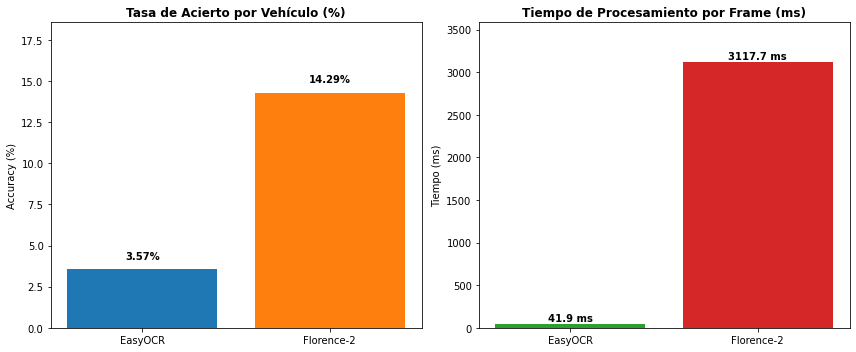


¡Proceso finalizado con éxito! Imagen 'comparativa_ocr_metricas.png' generada.


In [18]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import re

# =============================================================================
# 1. FUNCIONES AUXILIARES DE LIMPIEZA Y DISTANCIA
# =============================================================================

def normalizar_texto(texto):
    """Limpia el texto convirtiendo a mayúsculas y eliminando caracteres no alfanuméricos."""
    if pd.isna(texto):
        return ""
    texto = str(texto).upper().strip()
    return re.sub(r'[^A-Z0-9]', '', texto)

def distancia_levenshtein(s1, s2):
    """Calcula la distancia de edición de Levenshtein entre dos cadenas."""
    if len(s1) < len(s2):
        return distancia_levenshtein(s2, s1)
    if len(s2) == 0:
        return len(s1)
    previous_row = range(len(s2) + 1)
    for i, c1 in enumerate(s1):
        current_row = [i + 1]
        for j, c2 in enumerate(s2):
            insertions = previous_row[j + 1] + 1
            deletions = current_row[j] + 1
            substitutions = previous_row[j] + (c1 != c2)
            current_row.append(min(insertions, deletions, substitutions))
        previous_row = current_row
    return previous_row[-1]

def obtener_mejor_lectura(group):
    """Extrae la mejor predicción de un motor por vehículo (menor distancia Levenshtein)."""
    grupo_ordenado = group.sort_values(by=['dist_lev', 'acierto_exacto'], ascending=[True, False])
    mejor = grupo_ordenado.iloc[0]
    return pd.Series({
        'mejor_lectura': mejor['pred_norm'] if mejor['pred_norm'] != "" else "SIN_TEXTO",
        'dist_lev': mejor['dist_lev'],
        'acertado': "SÍ" if mejor['acierto_exacto'] else "NO"
    })

# =============================================================================
# 2. CARGA DE DATOS Y PREPROCESAMIENTO
# =============================================================================

print("Cargando archivos CSV...")
df_gt = pd.read_csv('ground_truth.csv')
df_res = pd.read_csv('resultados_finales_con_ocr.csv')

# Cruce con Verdad Absoluta (Ground Truth)
df_merged = pd.merge(
    df_res, 
    df_gt[['identificador_tracking', 'matricula_real', 'es_falso_positivo']], 
    on='identificador_tracking', 
    how='left'
)

# Filtrar falsos positivos para evaluar únicamente matrículas reales
df_valid = df_merged[df_merged['es_falso_positivo'] == 0].copy()

# Normalización de textos
df_valid['pred_norm'] = df_valid['texto_matricula'].apply(normalizar_texto)
df_valid['real_norm'] = df_valid['matricula_real'].apply(normalizar_texto)

# Cálculo de acierto exacto y distancia Levenshtein
df_valid['acierto_exacto'] = df_valid['pred_norm'] == df_valid['real_norm']
df_valid['dist_lev'] = df_valid.apply(lambda r: distancia_levenshtein(r['pred_norm'], r['real_norm']), axis=1)

# =============================================================================
# 3. CÁLCULO DE MÉTRICAS GLOBALES
# =============================================================================

# A) Métricas por Fotograma (Frame-level)
resumen_frame = df_valid.groupby('ocr_motor').agg(
    total_frames=('fotograma', 'count'),
    aciertos_exactos=('acierto_exacto', 'sum'),
    accuracy_frame_pct=('acierto_exacto', lambda x: x.mean() * 100),
    levenshtein_medio=('dist_lev', 'mean'),
    tiempo_medio_ms=('tiempo_procesamiento_ms', 'mean')
).reset_index()

# B) Métricas por Vehículo (Vehicle-level)
resumen_vehiculo = df_valid.groupby(['identificador_tracking', 'ocr_motor']).agg(
    acertado_al_menos_una_vez=('acierto_exacto', 'max'),
    menor_distancia_lev=('dist_lev', 'min')
).reset_index()

resumen_veh_global = resumen_vehiculo.groupby('ocr_motor').agg(
    vehiculos_totales=('identificador_tracking', 'nunique'),
    vehiculos_acertados=('acertado_al_menos_una_vez', 'sum'),
    accuracy_vehiculo_pct=('acertado_al_menos_una_vez', lambda x: x.mean() * 100),
    levenshtein_minimo_medio=('menor_distancia_lev', 'mean')
).reset_index()

# Mostrar métricas en consola
print("\n" + "="*60)
print("       MÉTRICAS POR FOTOGRAMA (FRAME-LEVEL)")
print("="*60)
print(resumen_frame.to_string(index=False))

print("\n" + "="*60)
print("       MÉTRICAS POR VEHÍCULO (VEHICLE-LEVEL)")
print("="*60)
print(resumen_veh_global.to_string(index=False))

# =============================================================================
# 4. TABLA DESGLOSADA POR VEHÍCULO Y GUARDADO EN CSV
# =============================================================================

# Compatible con todas las versiones de Pandas (sin include_groups)
df_desglose = df_valid.groupby(
    ['identificador_tracking', 'ocr_motor', 'real_norm']
).apply(obtener_mejor_lectura).reset_index()

tabla_comparativa = df_desglose.pivot(
    index=['identificador_tracking', 'real_norm'], 
    columns='ocr_motor', 
    values=['mejor_lectura', 'dist_lev', 'acertado']
)

df_desglose.to_csv('tabla_desglosada_vehiculos.csv', index=False)

print("\n" + "="*60)
print("       TABLA DESGLOSADA COMPARATIVA")
print("="*60)
print(tabla_comparativa.to_string())
print("\n¡Tabla desglosada guardada correctamente en 'tabla_desglosada_vehiculos.csv'!")

# =============================================================================
# 5. GENERACIÓN Y GUARDADO DE GRÁFICAS
# =============================================================================

plt.figure(figsize=(12, 5))

# Gráfico 1: Tasa de Acierto por Vehículo (%)
plt.subplot(1, 2, 1)
motores = resumen_veh_global['ocr_motor']
valores_acc = resumen_veh_global['accuracy_vehiculo_pct']
barras1 = plt.bar(motores, valores_acc, color=['#1f77b4', '#ff7f0e'])
plt.title('Tasa de Acierto por Vehículo (%)', fontweight='bold')
plt.ylabel('Accuracy (%)')
plt.ylim(0, max(valores_acc) * 1.3 if max(valores_acc) > 0 else 100)

for barra in barras1:
    yval = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2.0, 
        yval + 0.5, 
        f"{yval:.2f}%", 
        ha='center', 
        va='bottom', 
        fontweight='bold'
    )

# Gráfico 2: Tiempo Promedio por Frame (ms)
plt.subplot(1, 2, 2)
valores_tiempo = resumen_frame['tiempo_medio_ms']
barras2 = plt.bar(motores, valores_tiempo, color=['#2ca02c', '#d62728'])
plt.title('Tiempo de Procesamiento por Frame (ms)', fontweight='bold')
plt.ylabel('Tiempo (ms)')
plt.ylim(0, max(valores_tiempo) * 1.15)

for barra in barras2:
    yval = barra.get_height()
    plt.text(
        barra.get_x() + barra.get_width() / 2.0, 
        yval + 10, 
        f"{yval:.1f} ms", 
        ha='center', 
        va='bottom', 
        fontweight='bold'
    )

plt.tight_layout()
plt.savefig('comparativa_ocr_metricas.png', dpi=300)
plt.show()

print("\n¡Proceso finalizado con éxito! Imagen 'comparativa_ocr_metricas.png' generada.")